# 🏗️ La práctica de workers — tu primer pipeline

> 📽 *Vienes de las láminas POO-01 a POO-03: una clase = una cosa, y el orquestador.*

Tres workers y un orquestador, sobre **tu** clima de la clase pasada. El plan:
**leer → completar UN método → correr el pipeline con una línea**. Leer código ajeno
antes de escribir el propio: así se entra a cualquier proyecto real.

In [2]:
# ✅ Punto de control · el entorno y los datos
import os
try:
    import pandas as pd
    import matplotlib
    print("✅ Entorno listo")
except ImportError as e:
    print("⏳ Falta un paquete:", e, "— ¿kernel .venv?")
if os.path.exists("clima_cdmx.csv"):
    print("✅ clima_cdmx.csv encontrado")
else:
    print("⏳ No veo clima_cdmx.csv — corre la siguiente celda para volver a descargarlo")

✅ Entorno listo
⏳ No veo clima_cdmx.csv — corre la siguiente celda para volver a descargarlo


In [3]:
# 🛟 Plan B · re-descarga (solo si el punto de control lo pidió)
import os
if not os.path.exists("clima_cdmx.csv"):
    import requests, pandas as pd
    r = requests.get("https://archive-api.open-meteo.com/v1/archive", params={
        "latitude": 19.43, "longitude": -99.13, "start_date": "2024-01-01", "end_date": "2025-12-31",
        "daily": "temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,windspeed_10m_max,shortwave_radiation_sum",
        "timezone": "America/Mexico_City"}, timeout=30)
    pd.DataFrame(r.json()["daily"]).rename(columns={"time": "fecha"}).to_csv("clima_cdmx.csv", index=False)
    print("✅ re-descargado")
else:
    print("✅ ya estaba")

✅ re-descargado


## 1 · Los tres workers — LÉELOS antes de correr

Cada clase hace **una sola cosa**. Mientras lees, contesta con el dedo:
¿quién habla con el disco? ¿quién calcula? ¿quién dibuja? ¿quién conoce a quién?

*Fíjate: las columnas traen los **nombres crudos de la API** (`temperature_2m_max`, `precipitation_sum`…) — así llegan los datos reales. En la práctica de datos, al construir la base, los renombraremos.*

In [7]:
import pandas as pd


class Descargador:
    """Worker 1: consigue los datos — y NADA más."""

    def __init__(self, ruta):
        self.ruta = ruta

    def tabla(self):
        return pd.read_csv(self.ruta)


class Analista:
    """Worker 2: convierte y resume — y NADA más."""

    def __init__(self, umbral_aguacero=5.0):
        self.umbral = umbral_aguacero

    def resumen(self, tabla):
        return {
            "días": len(tabla),
            "t_max_promedio": round(tabla["temperature_2m_max"].mean(), 1),
            "lluvia_total_mm": round(tabla["precipitation_sum"].sum(), 1),
            "aguaceros": self.dias_de_aguacero(tabla),
        }

    def dias_de_aguacero(self, tabla):
        """Cuenta los días con lluvia FUERTE (> self.umbral mm).

        ✏️ TU CÓDIGO AQUÍ (2 líneas o incluso 1):
        pista: una máscara booleana sobre tabla["precipitation_sum"]
        y .sum() sobre la máscara — igual que con numpy.
        """
        return (tabla["precipitation_sum"] > self.umbral).sum()


class Graficador:
    """Worker 3: dibuja — y NADA más."""

    def serie(self, tabla, columna, titulo=""):
        ax = tabla[columna].plot(figsize=(10, 3), title=titulo)
        ax.set_xlabel("día")
        return ax

print("✅ tres workers definidos — ninguno importa a los otros")

✅ tres workers definidos — ninguno importa a los otros


## 2 · El orquestador — composición (TIENE-UN) en acción

Fíjate: `Clima` **tiene un** descargador, **tiene un** analista, **tiene un** graficador.
No hereda de nadie. Su código es corto porque **solo coordina**.

In [5]:
class Clima:
    """El orquestador: junta las piezas y dirige el flujo."""

    def __init__(self, ruta):
        self.descargador = Descargador(ruta)     # TIENE-UN worker
        self.analista = Analista()               # TIENE-UN worker
        self.graficador = Graficador()           # TIENE-UN worker

    def reporte(self):
        tabla = self.descargador.tabla()
        resumen = self.analista.resumen(tabla)
        self.graficador.serie(tabla, "precipitation_sum", "CDMX · lluvia diaria (mm)")
        return resumen

print("✅ orquestador definido")

✅ orquestador definido


## 3 · El pipeline, en UNA línea

🔮 **Antes de correr, predice:** si tu `dias_de_aguacero` sigue crudo, ¿qué va a pasar?

{'días': 731,
 't_max_promedio': 24.7,
 'lluvia_total_mm': 2654.4,
 'aguaceros': 176}

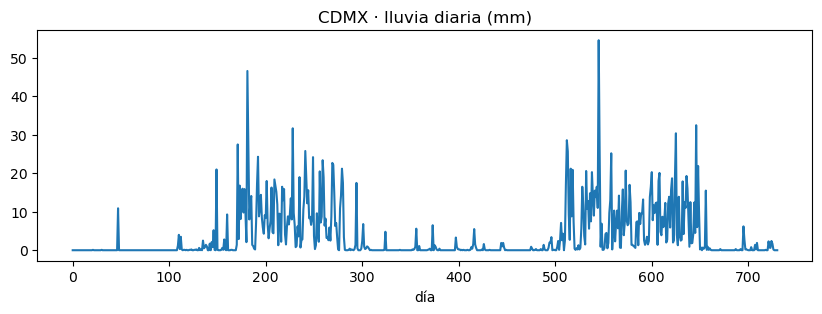

In [8]:
clima = Clima("clima_cdmx.csv")
clima.reporte()   # 🔮 DEBES VER: un resumen con 731 días y 178 aguaceros — y la gráfica de lluvia

## 🧠 Mini Reto · el costo del cambio, en carne propia

1. Crea `Analista(umbral_aguacero=20.0)` y pregúntale sus `dias_de_aguacero` — ¿cuántos
   quedan? *(¿Cuánto código tuviste que tocar? Esa es la gracia.)*
2. Dale al `Graficador` la serie de `temperature_2m_max` — sin tocar a nadie más.

In [ ]:
# Tu código aquí 👇


## ▶ El cierre

Ciclo git de siempre + `Fixes TAL-N` si abriste issue para esta práctica.
*▶ Volvemos a las láminas: las BASES DE DATOS.*